In [ ]:
import torch
import torch.nn as nn
import torch.fft
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

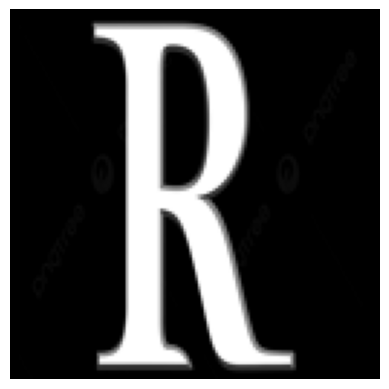

In [ ]:
img = Image.open("x.png").convert("L")
img = img.resize((128,128))

image = np.array(img, dtype=np.float32)
image = image / 255.0

target = torch.tensor(image).unsqueeze(0).unsqueeze(0)

plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
target_amp = torch.sqrt(target)

In [ ]:
def propagate(field, z):

    N = 128
    wavelength = 532e-9
    pixel = 10e-6

    fx = torch.fft.fftfreq(N, pixel)
    fy = torch.fft.fftfreq(N, pixel)

    FX, FY = torch.meshgrid(fx, fy, indexing="xy")

    k = 2 * torch.pi / wavelength

    H = torch.exp(
        1j * k * z *
        torch.sqrt(
            torch.clamp(
                1 - (wavelength*FX)**2 -
                (wavelength*FY)**2,
                min=0
            )
        )
    )

    return torch.fft.ifft2(
        torch.fft.fft2(field) * H
    )

In [ ]:
phase = torch.zeros_like(target_amp, requires_grad=True)

optimizer = torch.optim.Adam([phase], lr=0.05)

for i in range(2000):

    optimizer.zero_grad()

    hologram = torch.exp(1j * phase)

    reconstruction = propagate(hologram, 0.2)

    reconstruction = torch.abs(reconstruction)

    reconstruction = reconstruction / reconstruction.max()

    loss = torch.mean((reconstruction - target_amp) ** 2)

    loss.backward()
    optimizer.step()

    if i % 200 == 0:
        print(i, loss.item())

best_phase = torch.angle(torch.exp(1j * phase)).detach()

0 0.7536340355873108
200 0.1362706869840622
400 0.08979827910661697
600 0.05792153626680374
800 0.03932998329401016
1000 0.036921948194503784
1200 0.03327876329421997
1400 0.035453859716653824
1600 0.035869523882865906
1800 0.037508461624383926


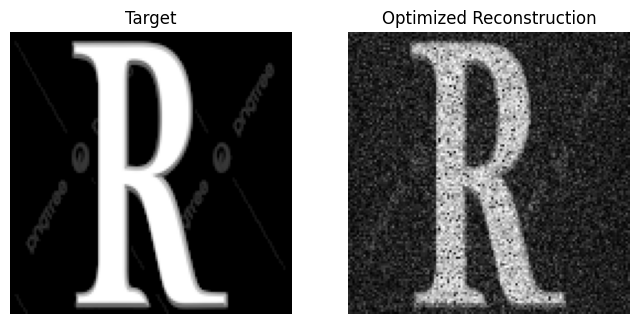

In [ ]:
hologram = torch.exp(1j * best_phase)

reconstruction = torch.abs(
    propagate(hologram, 0.2)
).detach()

reconstruction = reconstruction / reconstruction.max()

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(target_amp[0,0], cmap="gray")
plt.title("Target")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(reconstruction[0,0], cmap="gray")
plt.title("Optimized Reconstruction")
plt.axis("off")

plt.show()

In [ ]:
class NeuralHologram(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 1, 3, padding=1)
        )

    def forward(self, x):
        return torch.pi * torch.tanh(self.net(x))

In [ ]:
N = 128

x = torch.linspace(-1, 1, N)
y = torch.linspace(-1, 1, N)

X, Y = torch.meshgrid(x, y, indexing="xy")

X = X.unsqueeze(0).unsqueeze(0)
Y = Y.unsqueeze(0).unsqueeze(0)

network_input = torch.cat(
    [target_amp, X, Y],
    dim=1
)

print(network_input.shape)

torch.Size([1, 3, 128, 128])


In [ ]:
model = NeuralHologram()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
for i in range(5000):

    optimizer.zero_grad()

    predicted_phase = model(network_input)

    loss = torch.mean(
        1 - torch.cos(predicted_phase - best_phase)
    )

    loss.backward()

    optimizer.step()

    if i % 500 == 0:
        print(i, loss.item())

0 0.7173753976821899
500 0.44342830777168274
1000 0.41897809505462646
1500 0.39489370584487915
2000 0.3904500901699066
2500 0.3623807430267334
3000 0.36437591910362244
3500 0.34417644143104553
4000 0.3285154402256012
4500 0.3266928195953369


In [ ]:
predicted_phase = model(network_input).detach()

neural_hologram = torch.exp(1j * predicted_phase)

neural_reconstruction = torch.abs(
    propagate(neural_hologram, 0.2)
).detach()

neural_reconstruction = (
    neural_reconstruction /
    neural_reconstruction.max()
)

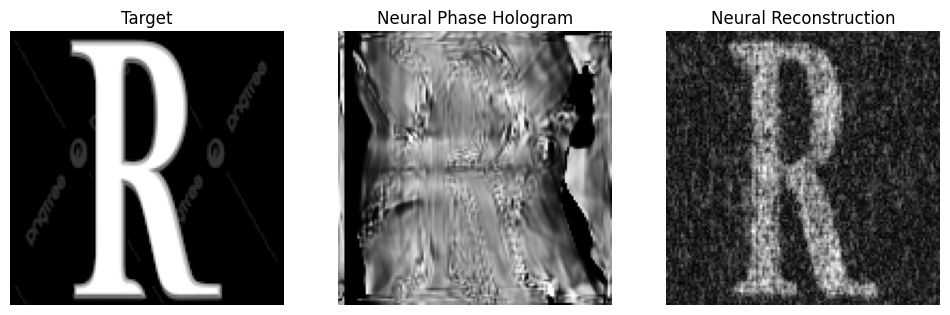

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(target_amp[0,0], cmap="gray")
plt.title("Target")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(predicted_phase[0,0], cmap="gray")
plt.title("Neural Phase Hologram")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(neural_reconstruction[0,0], cmap="gray")
plt.title("Neural Reconstruction")
plt.axis("off")

plt.show()

0 0.7237346768379211
500 0.04711871221661568
1000 0.041189465671777725
1500 0.037593938410282135
2000 0.04083976894617081
2500 0.03532617539167404
3000 0.034457430243492126
3500 0.03475876897573471
4000 0.03408424183726311
4500 0.03235470503568649


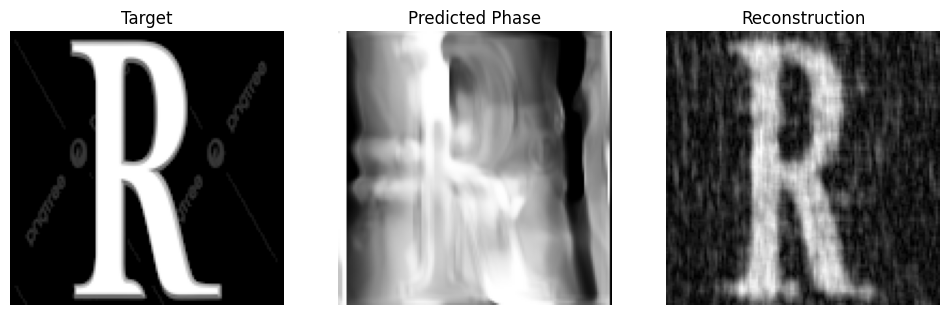

In [ ]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open("x.png").convert("L")
img = img.resize((128, 128))

image = np.array(img, dtype=np.float32)
image = image / 255.0

target = torch.tensor(image).unsqueeze(0).unsqueeze(0)
target_amp = torch.sqrt(target)

N = 128
wavelength = 532e-9
pixel = 10e-6

def propagate(field, z):

    fx = torch.fft.fftfreq(N, pixel)
    fy = torch.fft.fftfreq(N, pixel)

    FX, FY = torch.meshgrid(fx, fy, indexing="xy")

    k = 2 * torch.pi / wavelength

    H = torch.exp(
        1j * k * z *
        torch.sqrt(
            torch.clamp(
                1 - (wavelength * FX)**2 -
                (wavelength * FY)**2,
                min=0
            )
        )
    )

    return torch.fft.ifft2(
        torch.fft.fft2(field) * H
    )


class NeuralHologram(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 1, 3, padding=1)
        )

    def forward(self, x):
        return torch.pi * torch.tanh(self.net(x))


x = torch.linspace(-1, 1, N)
y = torch.linspace(-1, 1, N)

X, Y = torch.meshgrid(x, y, indexing="xy")

X = X.unsqueeze(0).unsqueeze(0)
Y = Y.unsqueeze(0).unsqueeze(0)

network_input = torch.cat(
    [target_amp, X, Y],
    dim=1
)

model = NeuralHologram()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

for i in range(5000):

    optimizer.zero_grad()

    predicted_phase = model(network_input)

    hologram = torch.exp(1j * predicted_phase)

    reconstruction = propagate(
        hologram,
        0.2
    )

    reconstruction = torch.abs(reconstruction)

    reconstruction = (
        reconstruction /
        reconstruction.max()
    )

    loss = torch.mean(
        (reconstruction - target_amp) ** 2
    )

    loss.backward()

    optimizer.step()

    if i % 500 == 0:
        print(i, loss.item())


predicted_phase = model(network_input).detach()

neural_hologram = torch.exp(
    1j * predicted_phase
)

neural_reconstruction = torch.abs(
    propagate(neural_hologram, 0.2)
).detach()

neural_reconstruction = (
    neural_reconstruction /
    neural_reconstruction.max()
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(target_amp[0, 0], cmap="gray")
plt.title("Target")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    predicted_phase[0, 0],
    cmap="gray"
)
plt.title("Predicted Phase")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    neural_reconstruction[0, 0],
    cmap="gray"
)
plt.title("Reconstruction")
plt.axis("off")

plt.show()



In [ ]:
import os
import zipfile
import numpy as np

zip_name = "archive.zip"

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("dataset")


In [ ]:

import os

print(os.listdir())
image_files = []

for root, dirs, files in os.walk("dataset"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            image_files.append(
                os.path.join(root, file)
            )

print("Total images found:", len(image_files))

np.random.seed(42)
np.random.shuffle(image_files)

image_files = image_files[:2000]

print("Images selected:", len(image_files))

['.config', 'neural_hologram_model.pth', 'dataset', 'archive.zip', 'sample_data']
Total images found: 13798
Images selected: 2000


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

N = 128

train_files, val_files = train_test_split(
    image_files,
    test_size=0.2,
    random_state=42
)

class HologramDataset(Dataset):

    def __init__(self, files, N=128):
        self.files = files
        self.N = N

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        img = Image.open(self.files[idx]).convert("L")
        img = img.resize((self.N, self.N))

        image = np.array(img, dtype=np.float32) / 255.0

        target = torch.tensor(image)

        target_amp = torch.sqrt(target)

        return target_amp.unsqueeze(0)

train_dataset = HologramDataset(train_files, N)
val_dataset = HologramDataset(val_files, N)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Number of training batches:", len(train_loader))

Training images: 1600
Validation images: 400
Number of training batches: 200


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N = 128
wavelength = 532e-9
pixel = 10e-6
z = 0.2

fx = torch.fft.fftfreq(N, pixel)
fy = torch.fft.fftfreq(N, pixel)

FX, FY = torch.meshgrid(fx, fy, indexing="xy")

k = 2 * torch.pi / wavelength

H = torch.exp(
    1j * k * z *
    torch.sqrt(
        torch.clamp(
            1 - (wavelength * FX)**2 -
            (wavelength * FY)**2,
            min=0
        )
    )
)

H = H.to(device)

x = torch.linspace(-1, 1, N, device=device)
y = torch.linspace(-1, 1, N, device=device)

X, Y = torch.meshgrid(x, y, indexing="xy")

X = X.unsqueeze(0).unsqueeze(0)
Y = Y.unsqueeze(0).unsqueeze(0)

print("Device:", device)
print("H shape:", H.shape)
print("X shape:", X.shape)
print("Y shape:", Y.shape)

Device: cpu
H shape: torch.Size([128, 128])
X shape: torch.Size([1, 1, 128, 128])
Y shape: torch.Size([1, 1, 128, 128])


In [ ]:
import torch.nn as nn

class NeuralHologram(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 1, 3, padding=1)
        )

    def forward(self, x):
        phase = self.net(x)
        phase = torch.pi * torch.tanh(phase)
        return phase

model = NeuralHologram().to(device)

print(model)

NeuralHologram(
  (net): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)


In [ ]:
target_amp = next(iter(train_loader))

target_amp = target_amp.to(device)

X_batch = X.expand(target_amp.shape[0], -1, -1, -1)
Y_batch = Y.expand(target_amp.shape[0], -1, -1, -1)

network_input = torch.cat(
    [target_amp, X_batch, Y_batch],
    dim=1
)

predicted_phase = model(network_input)

print("Target amplitude shape:", target_amp.shape)
print("Network input shape:", network_input.shape)
print("Predicted phase shape:", predicted_phase.shape)
print("Minimum phase:", predicted_phase.min().item())
print("Maximum phase:", predicted_phase.max().item())

Target amplitude shape: torch.Size([8, 1, 128, 128])
Network input shape: torch.Size([8, 3, 128, 128])
Predicted phase shape: torch.Size([8, 1, 128, 128])
Minimum phase: -0.06203852966427803
Maximum phase: 0.0917179062962532


In [ ]:
hologram = torch.exp(1j * predicted_phase)

reconstruction = torch.fft.ifft2(
    torch.fft.fft2(hologram) * H
)

reconstruction = torch.abs(reconstruction)

reconstruction = reconstruction / reconstruction.amax(
    dim=(-2, -1),
    keepdim=True
)

loss = torch.mean(
    (reconstruction - target_amp) ** 2
)

print("Hologram shape:", hologram.shape)
print("Reconstruction shape:", reconstruction.shape)
print("Loss:", loss.item())

Hologram shape: torch.Size([8, 1, 128, 128])
Reconstruction shape: torch.Size([8, 1, 128, 128])
Loss: 0.11850352585315704


In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 5

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for target_amp in train_loader:

        target_amp = target_amp.to(device)

        X_batch = X.expand(target_amp.shape[0], -1, -1, -1)
        Y_batch = Y.expand(target_amp.shape[0], -1, -1, -1)

        network_input = torch.cat(
            [target_amp, X_batch, Y_batch],
            dim=1
        )

        optimizer.zero_grad()

        predicted_phase = model(network_input)

        hologram = torch.exp(
            1j * predicted_phase
        )

        reconstruction = torch.fft.ifft2(
            torch.fft.fft2(hologram) * H
        )

        reconstruction = torch.abs(reconstruction)

        reconstruction = reconstruction / reconstruction.amax(
            dim=(-2, -1),
            keepdim=True
        )

        loss = torch.mean(
            (reconstruction - target_amp) ** 2
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    print(
        "Epoch:",
        epoch + 1,
        "Loss:",
        average_loss
    )

Epoch: 1 Loss: 0.03991607229225338
Epoch: 2 Loss: 0.03341356468386948
Epoch: 3 Loss: 0.0329488012380898
Epoch: 4 Loss: 0.03202827702276409
Epoch: 5 Loss: 0.03211582612246275


In [ ]:
torch.save(
    model.state_dict(),
    "neural_hologram_model.pth"
)

print("Model saved successfully")

Model saved successfully


Input shape: torch.Size([1, 3, 128, 128])
Predicted phase shape: torch.Size([1, 1, 128, 128])
Hologram shape: torch.Size([1, 1, 128, 128])
Reconstruction shape: torch.Size([1, 1, 128, 128])


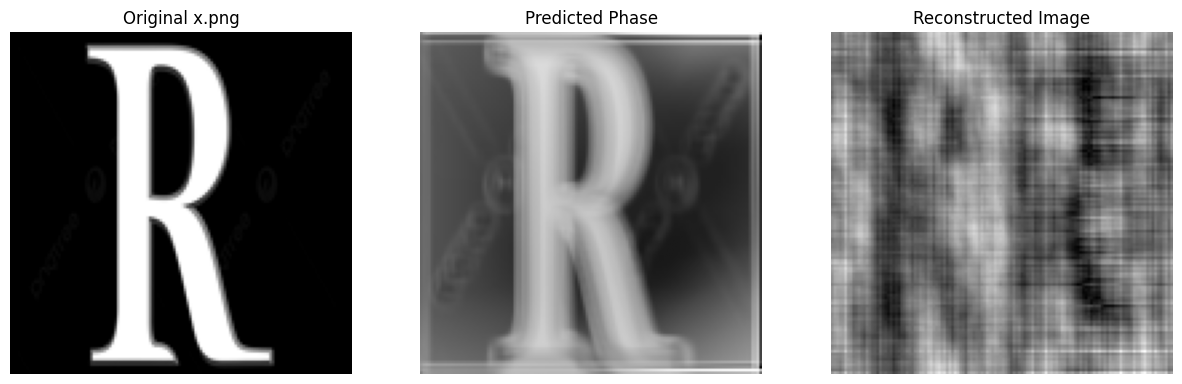

In [ ]:
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt

model = NeuralHologram().to(device)

model.load_state_dict(
    torch.load(
        "neural_hologram_model.pth",
        map_location=device
    )
)

model.eval()

image_name = "x.png"

img = Image.open(image_name).convert("L")
img = img.resize((N, N))

image = np.array(
    img,
    dtype=np.float32
) / 255.0

target = torch.tensor(
    image,
    dtype=torch.float32
)

target_amp = torch.sqrt(target)

target_amp = target_amp.unsqueeze(0).unsqueeze(0).to(device)

network_input = torch.cat(
    [target_amp, X, Y],
    dim=1
)

with torch.no_grad():

    predicted_phase = model(network_input)

    hologram = torch.exp(
        1j * predicted_phase
    )

    reconstruction = torch.fft.ifft2(
        torch.fft.fft2(hologram) * H
    )

    reconstruction = torch.abs(reconstruction)

    reconstruction = reconstruction / reconstruction.amax()

original = image
reconstructed = reconstruction.squeeze().cpu().numpy()
phase = predicted_phase.squeeze().cpu().numpy()

print("Input shape:", network_input.shape)
print("Predicted phase shape:", predicted_phase.shape)
print("Hologram shape:", hologram.shape)
print("Reconstruction shape:", reconstruction.shape)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray")
plt.title("Original x.png")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(phase, cmap="gray")
plt.title("Predicted Phase")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(reconstructed, cmap="gray")
plt.title("Reconstructed Image")
plt.axis("off")

plt.show()

Testing training image: dataset/natural_images/fruit/fruit_0727.jpg
Input shape: torch.Size([1, 3, 128, 128])
Predicted phase shape: torch.Size([1, 1, 128, 128])
Hologram shape: torch.Size([1, 1, 128, 128])
Reconstruction shape: torch.Size([1, 1, 128, 128])
Reconstruction amplitude MSE: 0.17410920560359955


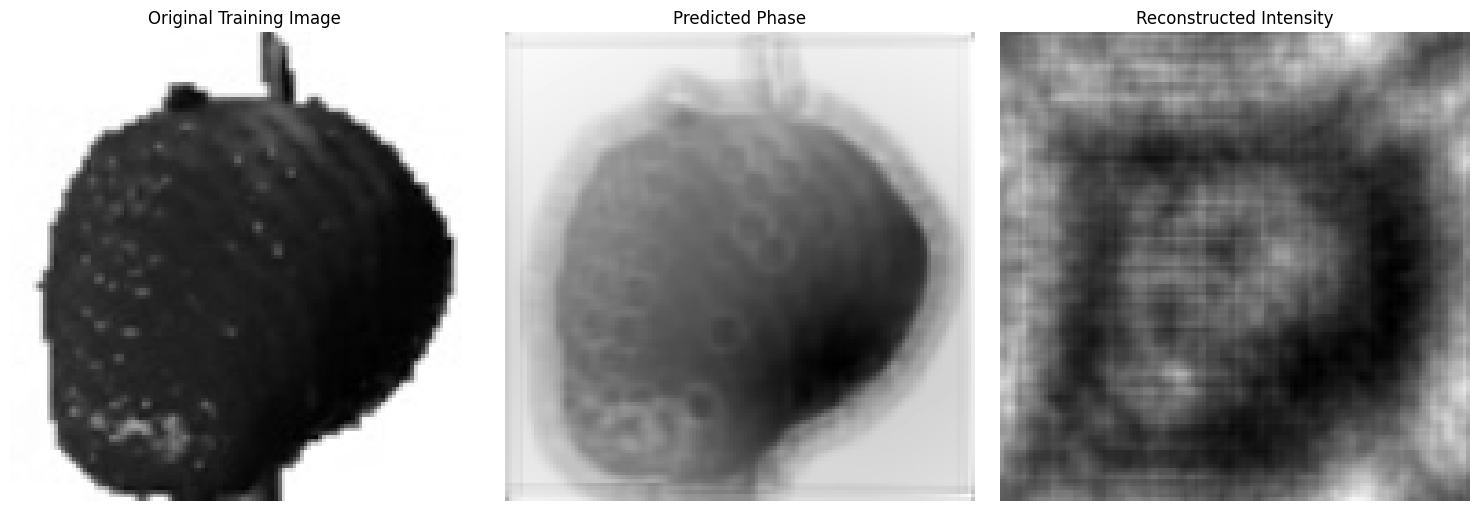

In [ ]:

from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt

model = NeuralHologram().to(device)

model.load_state_dict(
    torch.load(
        "neural_hologram_model.pth",
        map_location=device
    )
)

model.eval()

image_name = train_files[0]

print("Testing training image:", image_name)

img = Image.open(image_name).convert("L")
img = img.resize((N, N))

image = np.array(
    img,
    dtype=np.float32
) / 255.0

target = torch.tensor(
    image,
    dtype=torch.float32
)

target_amp = torch.sqrt(target)

target_amp = target_amp.unsqueeze(0).unsqueeze(0).to(device)

network_input = torch.cat(
    [target_amp, X, Y],
    dim=1
)

with torch.no_grad():

    predicted_phase = model(network_input)

    hologram = torch.exp(
        1j * predicted_phase
    )

    field = torch.fft.ifft2(
        torch.fft.fft2(hologram) * H
    )

    reconstruction_amplitude = torch.abs(field)

    reconstruction_intensity = (
        reconstruction_amplitude ** 2
    )

    reconstruction_intensity = (
        reconstruction_intensity /
        reconstruction_intensity.amax()
    )

original = image

reconstructed = (
    reconstruction_intensity
    .squeeze()
    .cpu()
    .numpy()
)

phase = (
    predicted_phase
    .squeeze()
    .cpu()
    .numpy()
)

print("Input shape:", network_input.shape)
print("Predicted phase shape:", predicted_phase.shape)
print("Hologram shape:", hologram.shape)
print("Reconstruction shape:", reconstruction_intensity.shape)

reconstruction_loss = torch.mean(
    (
        reconstruction_amplitude -
        target_amp
    ) ** 2
)

print(
    "Reconstruction amplitude MSE:",
    reconstruction_loss.item()
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(
    original,
    cmap="gray"
)
plt.title("Original Training Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    phase,
    cmap="gray"
)
plt.title("Predicted Phase")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    reconstructed,
    cmap="gray"
)
plt.title("Reconstructed Intensity")
plt.axis("off")

plt.tight_layout()
plt.show()

